# Credit Risk Scoring — Notebook 2: Modelling, Benchmarking & Explainability
## India Personal Loan Default Risk 2026

---

### What This Notebook Covers
| Step | Description |
|:---|:---|
| **Step 4b** | Leakage-Free Preprocessing Pipeline (`ColumnTransformer` + `Pipeline`) |
| **Step 5** | Multi-Model Benchmarking — 4 classifiers on identical CV folds |
| **Step 6a** | Threshold Optimisation — business cost matrix & optimal cutoff |
| **Step 6b** | SHAP Explainability — global feature importance + individual explanations |
| **Step 6c** | Error Analysis — who does the model miss and why? |

> **Pre-requisite:** Run `notebooks/01_EDA_and_Data_Cleaning.ipynb` first to generate `data/processed/train.csv` and `data/processed/test.csv`.

---
## Setup — Imports & Configuration

In [1]:
import sys, os, time, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import joblib

# ── Scikit-learn ──────────────────────────────────────────────
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
 roc_auc_score, average_precision_score,
 precision_score, recall_score, f1_score,
 roc_curve, precision_recall_curve,
 confusion_matrix, ConfusionMatrixDisplay
)

# ── Visual style ─────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='Set2', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120})
COLORS = {'default': '#E74C3C', 'non_default': '#2ECC71', 'blue': '#3498DB', 'orange': '#E67E22'}

# ── Paths & constants ─────────────────────────────────────────
TRAIN_PATH = '../data/processed/train.csv'
TEST_PATH = '../data/processed/test.csv'
MODELS_DIR = '../models/'
RESULTS_DIR = '../results/'
TARGET = 'default_flag'
RANDOM_STATE = 42
CV_FOLDS = 5
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print('Imports complete.')

Imports complete.


### Load Cleaned Train & Test Sets

In [2]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

print(f'Train → {X_train.shape[0]:,} rows × {X_train.shape[1]} cols | default rate: {y_train.mean()*100:.2f}%')
print(f'Test → {X_test.shape[0]:,} rows × {X_test.shape[1]} cols | default rate: {y_test.mean()*100:.2f}%')

Train → 20,000 rows × 19 cols | default rate: 6.14%
Test → 5,000 rows × 19 cols | default rate: 6.14%


---
# STEP 4b — Leakage-Free Preprocessing Pipeline

> **Why use `sklearn.Pipeline`?** 
> A `Pipeline` chains preprocessing steps and the model into a single object. When you call `pipe.fit(X_train, y_train)`, every step (imputer, scaler, encoder) is fitted **only** on `X_train`. When you call `pipe.predict(X_test)`, those same fitted transformers are applied to `X_test` — the test set never influences the fitted statistics.
>
> This eliminates the most common form of data leakage in Jupyter notebooks, where analysts often run `scaler.fit(X)` on the full dataset, not realising that test information contaminates the training distribution.
>
> **`ColumnTransformer`** lets us apply different pipelines to different column groups:
> - **Numeric columns** → `SimpleImputer(median)` → `StandardScaler`
> - **Categorical columns** → `SimpleImputer(most_frequent)` → `OneHotEncoder`

### 4b.1 Feature Engineering Transformer (sklearn-compatible)

In [3]:
def add_financial_ratios(df_input):
    """Adds 7 Indian banking domain-specific financial ratios."""
    df_out = df_input.copy()
    inc = df_out['monthly_income_inr'].replace(0, np.nan)
    tenure = df_out['loan_tenure_months'].replace(0, np.nan)

    df_out['emi_to_income_ratio'] = (df_out['existing_emi_monthly_inr'] / inc).fillna(0).round(4)
    df_out['loan_to_annual_income_ratio'] = (df_out['loan_amount_requested_inr'] / (inc * 12)).fillna(0).round(4)
    df_out['estimated_monthly_installment'] = (df_out['loan_amount_requested_inr'] / tenure).fillna(0).round(2)
    df_out['installment_to_income_ratio'] = (df_out['estimated_monthly_installment'] / inc).fillna(0).round(4)
    total_emi = df_out['existing_emi_monthly_inr'].fillna(0) + df_out['estimated_monthly_installment'].fillna(0)
    df_out['total_obligations_ratio'] = (total_emi / inc).fillna(0).round(4)
    deficit = (900 - df_out['cibil_score'].fillna(750)) / 100
    df_out['credit_hunger_index'] = (df_out['num_credit_inquiries_last_6m'].fillna(0) * deficit).round(4)
    df_out['cibil_band_code'] = df_out['cibil_score'].apply(
        lambda s: 0 if pd.isna(s) or s < 650 else 1 if s < 700 else 2 if s < 750 else 3
    )
    return df_out


class FeatureEngineer(BaseEstimator, TransformerMixin):
    """sklearn wrapper — fits to nothing, transforms by adding ratio columns."""
    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError('FeatureEngineer expects a DataFrame')
        return add_financial_ratios(X)

print('FeatureEngineer transformer defined.')

FeatureEngineer transformer defined.


### 4b.2 Define Column Groups & ColumnTransformer

In [4]:
NUMERICAL_COLS = [
 'age', 'bank_account_vintage_years', 'monthly_income_inr',
 'existing_loans_count', 'existing_emi_monthly_inr',
 'credit_utilization_ratio_pct', 'num_credit_inquiries_last_6m',
 'late_payments_last_12m', 'loan_amount_requested_inr',
 'loan_tenure_months', 'cibil_score', 'interest_rate_offered_pct',
 # engineered:
 'emi_to_income_ratio', 'loan_to_annual_income_ratio',
 'estimated_monthly_installment', 'installment_to_income_ratio',
 'total_obligations_ratio', 'credit_hunger_index', 'cibil_band_code'
]
CATEGORICAL_COLS = [
 'gender', 'marital_status', 'city_tier', 'state',
 'employment_type', 'loan_purpose', 'collateral_provided'
]

numeric_pipeline = Pipeline([
 ('imputer', SimpleImputer(strategy='median')), # fill missing with column median
 ('scaler', StandardScaler()), # zero-mean, unit-variance (needed for LR)
])

categorical_pipeline = Pipeline([
 ('imputer', SimpleImputer(strategy='most_frequent')), # fill with mode
 ('encoder', OneHotEncoder(handle_unknown='ignore', # drop unseen categories at predict time
 sparse_output=False)),
])

preprocessor = ColumnTransformer(
 transformers=[
 ('num', numeric_pipeline, NUMERICAL_COLS),
 ('cat', categorical_pipeline, CATEGORICAL_COLS),
 ],
 remainder='drop',
 verbose_feature_names_out=False
)

print('ColumnTransformer defined.')
print(f' Numeric features: {len(NUMERICAL_COLS)}')
print(f' Categorical features: {len(CATEGORICAL_COLS)}')

ColumnTransformer defined.
 Numeric features: 19
 Categorical features: 7


### 4b.3 Build Full Pipeline (Feature Engineering → Preprocessing → Classifier)

> The full 3-step pipeline ensures:
> 1. **Feature engineering runs inside CV folds** — no future information bleeds in
> 2. **Imputer medians are computed on the fold's train split** — not the full dataset
> 3. **OHE categories are determined by the fold's train data** — unseen categories at test-time are safely ignored via `handle_unknown='ignore'`

In [5]:
def build_pipeline(classifier):
 """Wraps feature engineering + preprocessing + classifier into one Pipeline."""
 return Pipeline([
 ('feature_engineering', FeatureEngineer()),
 ('preprocessor', preprocessor),
 ('classifier', classifier),
 ])

# Quick sanity check — transform one row to confirm the pipeline chain works
from sklearn.linear_model import LogisticRegression as LR
test_pipe = build_pipeline(LR(max_iter=10, class_weight='balanced'))
test_pipe.fit(X_train.head(500), y_train.head(500))
out_shape = test_pipe.named_steps['preprocessor'].transform(
 test_pipe.named_steps['feature_engineering'].transform(X_train.head(1))
).shape
print(f'Pipeline sanity check passed.')
print(f' Input columns: {X_train.shape[1]}')
print(f' After pipeline: {out_shape[1]} features (original + engineered + OHE expanded)')

Pipeline sanity check passed.
 Input columns: 19
 After pipeline: 59 features (original + engineered + OHE expanded)


---
# STEP 5 — Multi-Model Benchmarking

> **Why compare multiple models?** 
> No single algorithm is universally best. Comparing model families tells us:
> - How much complexity do we actually need? (Logistic Regression vs Random Forest)
> - Is the problem linearly separable, or do we need non-linear boundaries? 
> - What is the speed-accuracy tradeoff? (Decision Tree: 0.29s vs HistGB: 3.04s)
>
> **Model Families We Compare:**
> | Model | Family | Key Strength |
> |:---|:---|:---|
> | Logistic Regression | Linear | Fastest, most interpretable, coefficients = feature weights |
> | Decision Tree | Single Tree | Visualisable decision rules, non-linear boundaries |
> | Random Forest | Bagging Ensemble | Reduces Decision Tree overfitting via averaging |
> | HistGradientBoosting | Boosting Ensemble | SOTA tabular model — builds trees sequentially on errors |
>
> All models use `class_weight='balanced'` to address the 6.14% default minority.

### 5.1 Define Models

In [6]:
MODELS = {
 'Logistic Regression': LogisticRegression(
 max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE
 ),
 'Decision Tree': DecisionTreeClassifier(
 max_depth=8, class_weight='balanced', random_state=RANDOM_STATE
 ),
 'Random Forest': RandomForestClassifier(
 n_estimators=200, max_depth=12, class_weight='balanced',
 n_jobs=1, random_state=RANDOM_STATE
 ),
 'Gradient Boosting (HistGB)': HistGradientBoostingClassifier(
 max_iter=300, max_depth=6, learning_rate=0.05, random_state=RANDOM_STATE
 ),
}

print('Models registered for benchmarking:')
for name in MODELS:
 print(f' ▸ {name}')

Models registered for benchmarking:
 ▸ Logistic Regression
 ▸ Decision Tree
 ▸ Random Forest
 ▸ Gradient Boosting (HistGB)


### 5.2 Stratified K-Fold Cross-Validation

> **Why Stratified K-Fold?** 
> With 6.14% default rate, random K-Fold folds can have highly variable minority-class proportions. `StratifiedKFold` forces each fold to maintain the original class ratio — giving us stable, comparable CV scores across all 5 folds.

In [7]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCORERS = {
 'roc_auc': 'roc_auc',
 'average_precision': 'average_precision', # = PR-AUC
 'recall': 'recall',
 'precision': 'precision',
 'f1': 'f1',
}

cv_results_all = {}
print(f'Running {CV_FOLDS}-Fold Stratified CV on {len(MODELS)} models...\n')

for name, clf in MODELS.items():
 pipe = build_pipeline(clf)
 t0 = time.perf_counter()
 cv_res = cross_validate(pipe, X_train, y_train, cv=cv,
 scoring=SCORERS, return_train_score=False, n_jobs=1)
 elapsed = time.perf_counter() - t0
 cv_results_all[name] = cv_res

 roc = cv_res['test_roc_auc'].mean()
 pr = cv_res['test_average_precision'].mean()
 rec = cv_res['test_recall'].mean()
 f1 = cv_res['test_f1'].mean()
 print(f' {name:<35} ROC-AUC={roc:.4f} PR-AUC={pr:.4f} '
 f'Recall={rec:.4f} F1={f1:.4f} [{elapsed:.1f}s]')

Running 5-Fold Stratified CV on 4 models...



 Logistic Regression                 ROC-AUC=0.8560 PR-AUC=0.3767 Recall=0.7745 F1=0.3042 [0.7s]


 Decision Tree                       ROC-AUC=0.7290 PR-AUC=0.2465 Recall=0.6645 F1=0.2564 [1.2s]


 Random Forest                       ROC-AUC=0.8438 PR-AUC=0.3071 Recall=0.5294 F1=0.3529 [17.8s]


 Gradient Boosting (HistGB)          ROC-AUC=0.8460 PR-AUC=0.3384 Recall=0.1213 F1=0.2012 [5.9s]


### 5.3 Cross-Validation Summary Table

In [8]:
cv_rows = []
for name, res in cv_results_all.items():
    row = {'Model': name}
    for metric in SCORERS:
        vals = res[f'test_{metric}']
        row[f'{metric}_mean'] = round(vals.mean(), 4)
        row[f'{metric}_std'] = round(vals.std(), 4)
    cv_rows.append(row)

cv_df = pd.DataFrame(cv_rows).set_index('Model')
# Display only mean columns for clarity
mean_cols = [c for c in cv_df.columns if '_mean' in c]
cv_df[mean_cols].rename(columns=lambda c: c.replace('_mean', '')) \
    .style.highlight_max(props='background-color: #196f3d; color: #ffffff; font-weight: bold;')

,roc_auc,average_precision,recall,precision,f1
Model,,,,,
Logistic Regression,0.856000,0.376700,0.774500,0.189400,0.304200
Decision Tree,0.729000,0.246500,0.664500,0.159000,0.256400
Random Forest,0.843800,0.307100,0.529400,0.265000,0.352900
Gradient Boosting (HistGB),0.846000,0.338400,0.121300,0.596600,0.201200


### 5.4 Train Final Models on Full Train Set & Evaluate on Test Set

> After CV tells us the **relative ordering** of models, we fit each one on the full training set and evaluate on the held-out test set for the **final reported numbers**. The test set is touched exactly once — here.

In [9]:
test_rows = []
fitted_pipelines = {}
roc_data, pr_data, cm_data = {}, {}, {}

print('Fitting final models on full Train set -> evaluating on Test set...\n')

for name, clf in MODELS.items():
    pipe = build_pipeline(clf)

    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_t = time.perf_counter() - t0

    t1 = time.perf_counter()
    y_prob = pipe.predict_proba(X_test)[:, 1]
    pred_t = time.perf_counter() - t1
    y_pred = (y_prob >= 0.50).astype(int)

    metrics = {
        'Model': name,
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4),
        'PR-AUC': round(average_precision_score(y_test, y_prob), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred, zero_division=0), 4),
        'F1-Score': round(f1_score(y_test, y_pred, zero_division=0), 4),
        'Fit Time(s)': round(fit_t, 2),
        'Pred Time(s)': round(pred_t, 4),
    }
    test_rows.append(metrics)
    fitted_pipelines[name] = pipe

    # Save model
    safe = name.replace(' ', '_').replace('(', '').replace(')', '')
    joblib.dump(pipe, f'{MODELS_DIR}{safe}.joblib')

    # Curve data
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, metrics['ROC-AUC'])
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    pr_data[name] = (prec, rec, metrics['PR-AUC'])
    cm_data[name] = confusion_matrix(y_test, y_pred)

    print(
        f'  {name:<35} ROC-AUC={metrics["ROC-AUC"]} PR-AUC={metrics["PR-AUC"]} '
        f'Recall={metrics["Recall"]} F1={metrics["F1-Score"]} fit={fit_t:.2f}s'
    )

test_df = pd.DataFrame(test_rows).set_index('Model')
test_df.to_csv(f'{RESULTS_DIR}test_benchmark.csv')
print('\nAll models fitted and saved.')

Fitting final models on full Train set -> evaluating on Test set...



  Logistic Regression                 ROC-AUC=0.8728 PR-AUC=0.3832 Recall=0.7883 F1=0.3147 fit=0.24s


  Decision Tree                       ROC-AUC=0.7676 PR-AUC=0.2388 Recall=0.7101 F1=0.2686 fit=0.40s


  Random Forest                       ROC-AUC=0.8667 PR-AUC=0.3371 Recall=0.5961 F1=0.394 fit=4.84s


  Gradient Boosting (HistGB)          ROC-AUC=0.8719 PR-AUC=0.3726 Recall=0.1433 F1=0.2353 fit=0.62s

All models fitted and saved.


### 5.5 Benchmark Summary Table

In [10]:
highlight_cols = ['ROC-AUC', 'PR-AUC', 'Recall', 'Precision', 'F1-Score']
test_df[highlight_cols + ['Fit Time(s)','Pred Time(s)']]\
 .style\
 .format('{:.4f}', subset=highlight_cols)\
    .highlight_max(subset=highlight_cols, props='background-color: #196f3d; color: #ffffff; font-weight: bold;')\
    .highlight_min(subset=['Fit Time(s)','Pred Time(s)'], props='background-color: #196f3d; color: #ffffff; font-weight: bold;')\
 .set_caption('Test-Set Benchmark — Green = Best per column')

,ROC-AUC,PR-AUC,Recall,Precision,F1-Score,Fit Time(s),Pred Time(s)
Model,,,,,,,
Logistic Regression,0.8728,0.3832,0.7883,0.1966,0.3147,0.240000,0.036300
Decision Tree,0.7676,0.2388,0.7101,0.1657,0.2686,0.400000,0.021200
Random Forest,0.8667,0.3371,0.5961,0.2942,0.3940,4.840000,0.131700
Gradient Boosting (HistGB),0.8719,0.3726,0.1433,0.6567,0.2353,0.620000,0.039700


### 5.6 ROC Curves — All Models

> **ROC-AUC** measures a model's ability to rank risky borrowers higher than safe ones **across all possible thresholds**. A score of 0.87 means: given a random defaulter and a random non-defaulter, the model assigns a higher probability to the defaulter 87% of the time.

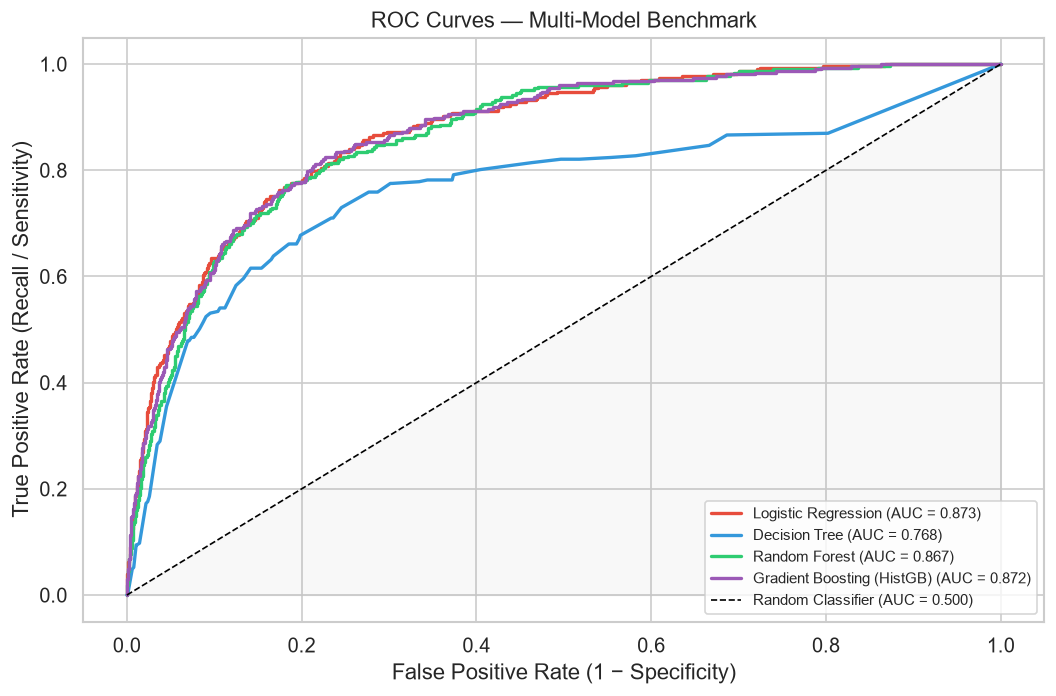

All 4 models significantly outperform the random baseline (AUC=0.5).
 The gap between them is clearer in the Precision-Recall curve below.


In [11]:
fig, ax = plt.subplots(figsize=(9, 6))
palette = ['#E74C3C', '#3498DB', '#2ECC71', '#9B59B6']
for (name, (fpr, tpr, auc)), color in zip(roc_data.items(), palette):
 ax.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})',
 linewidth=2, color=color)
ax.plot([0,1],[0,1], 'k--', linewidth=1, label='Random Classifier (AUC = 0.500)')
ax.fill_between([0,1],[0,1], alpha=0.05, color='grey')
ax.set(xlabel='False Positive Rate (1 − Specificity)',
 ylabel='True Positive Rate (Recall / Sensitivity)',
 title='ROC Curves — Multi-Model Benchmark')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}roc_curves.png', dpi=150)
plt.show()
print('All 4 models significantly outperform the random baseline (AUC=0.5).')
print(' The gap between them is clearer in the Precision-Recall curve below.')

### 5.7 Precision-Recall Curves — The Right Metric for Imbalanced Data

> **Why PR-AUC matters more than ROC-AUC here:** 
> With 93.86% non-defaults, the ROC curve is dominated by the majority class and can look artificially good. The Precision-Recall curve focuses **entirely on the minority (default) class** — it shows how well the model identifies actual defaulters while keeping false alarms manageable.
>
> A PR-AUC of 0.38 means: across all threshold settings, the model achieves an average precision of 38% when detecting the 6.14% default minority. A random classifier would score ~6.14% (the base rate).

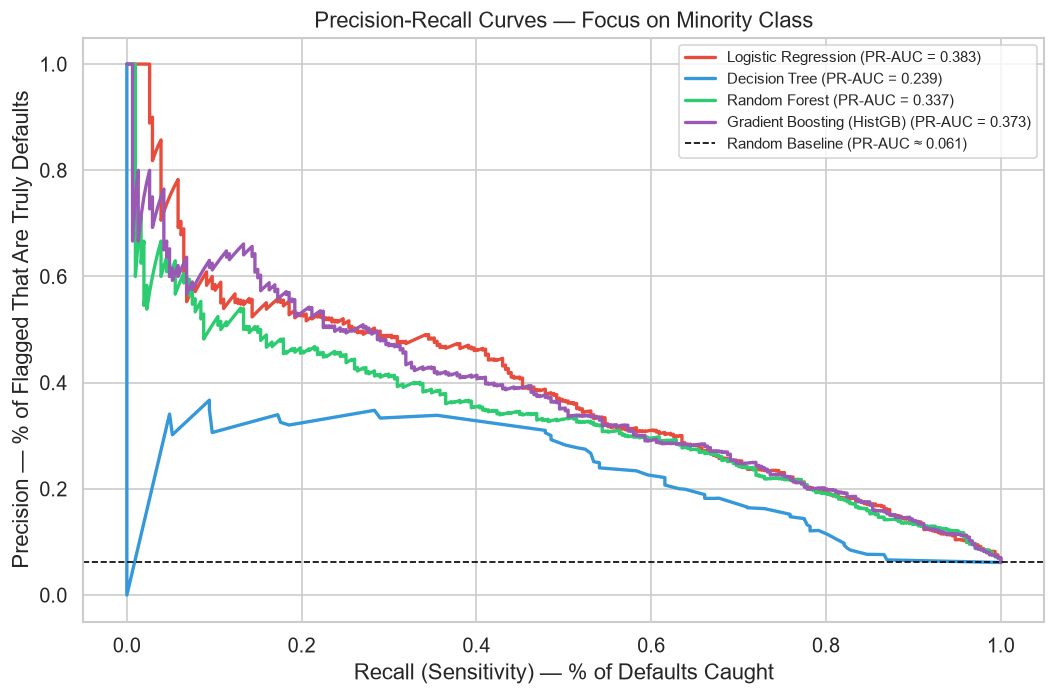


Best by PR-AUC → Logistic Regression (0.3832)
Best by F1-Score → Random Forest (0.394)


In [12]:
fig, ax = plt.subplots(figsize=(9, 6))
baseline = y_test.mean()
for (name, (prec, rec, ap)), color in zip(pr_data.items(), palette):
 ax.plot(rec, prec, label=f'{name} (PR-AUC = {ap:.3f})',
 linewidth=2, color=color)
ax.axhline(baseline, color='black', linestyle='--', linewidth=1,
 label=f'Random Baseline (PR-AUC ≈ {baseline:.3f})')
ax.set(xlabel='Recall (Sensitivity) — % of Defaults Caught',
 ylabel='Precision — % of Flagged That Are Truly Defaults',
 title='Precision-Recall Curves — Focus on Minority Class')
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}pr_curves.png', dpi=150)
plt.show()

best_pr = test_df['PR-AUC'].idxmax()
best_f1 = test_df['F1-Score'].idxmax()
print(f'\nBest by PR-AUC → {best_pr} ({test_df.loc[best_pr,"PR-AUC"]})')
print(f'Best by F1-Score → {best_f1} ({test_df.loc[best_f1,"F1-Score"]})')

### 5.8 Metric Comparison Bar Chart

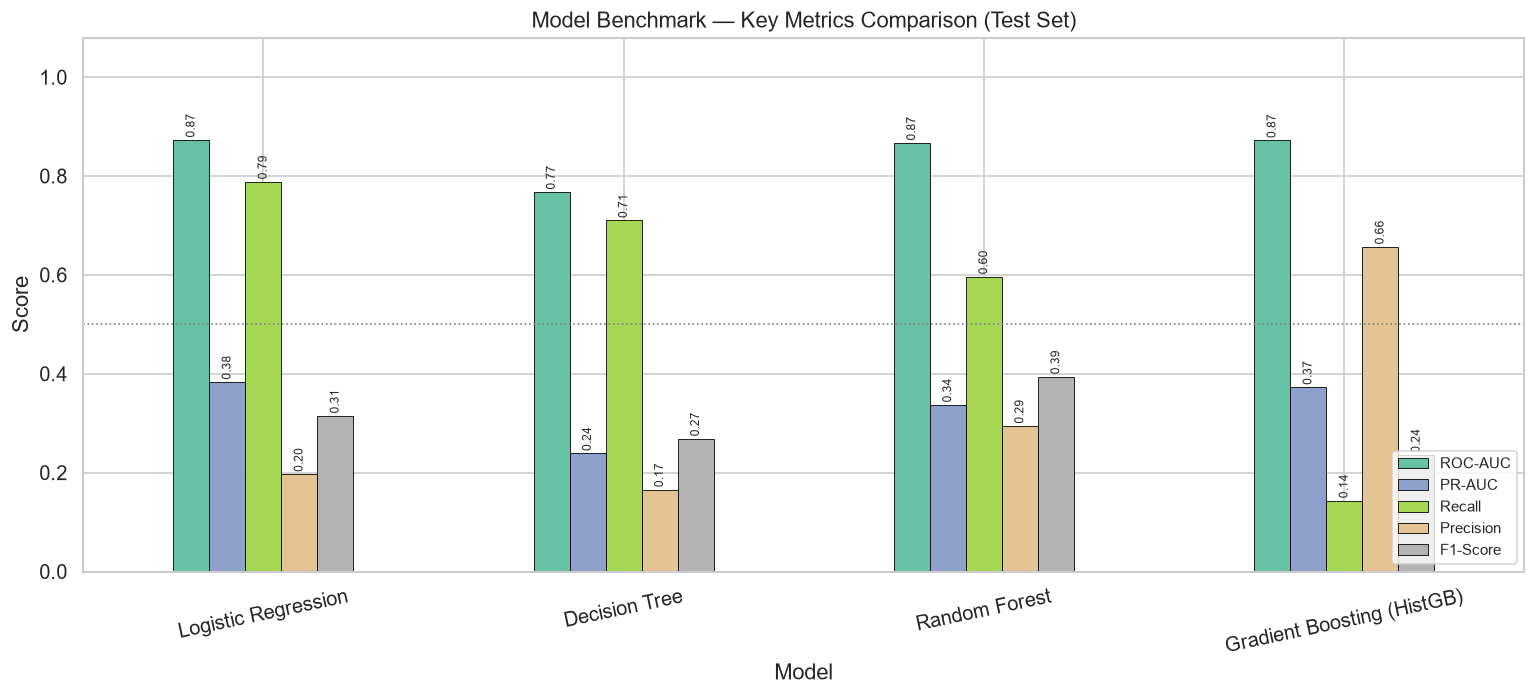

In [13]:
metrics_to_plot = ['ROC-AUC', 'PR-AUC', 'Recall', 'Precision', 'F1-Score']
ax = test_df[metrics_to_plot].plot(
    kind='bar', figsize=(13, 6), colormap='Set2',
    rot=12, edgecolor='black', linewidth=0.5
)
ax.set(
    title='Model Benchmark — Key Metrics Comparison (Test Set)',
    ylabel='Score', ylim=(0, 1.08)
)
ax.legend(loc='lower right', fontsize=9)
ax.axhline(0.5, color='grey', linestyle=':', linewidth=1)
for p in ax.patches:
    if p.get_height() > 0.01:
        ax.text(
            p.get_x() + p.get_width() / 2, p.get_height() + 0.01,
            f'{p.get_height():.2f}', ha='center', fontsize=7, rotation=90
        )
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}benchmark_bar.png', dpi=150)
plt.show()

### 5.9 Confusion Matrices

> **Reading a confusion matrix for imbalanced credit risk:**
> - **True Positive (TP)**: Correctly flagged defaulter → model protects the lender 
> - **False Negative (FN)**: Missed defaulter → **most costly error** (bad loan approved) 
> - **False Positive (FP)**: Good borrower wrongly rejected → lost interest revenue 
> - **True Negative (TN)**: Correctly approved safe borrower → happy customer

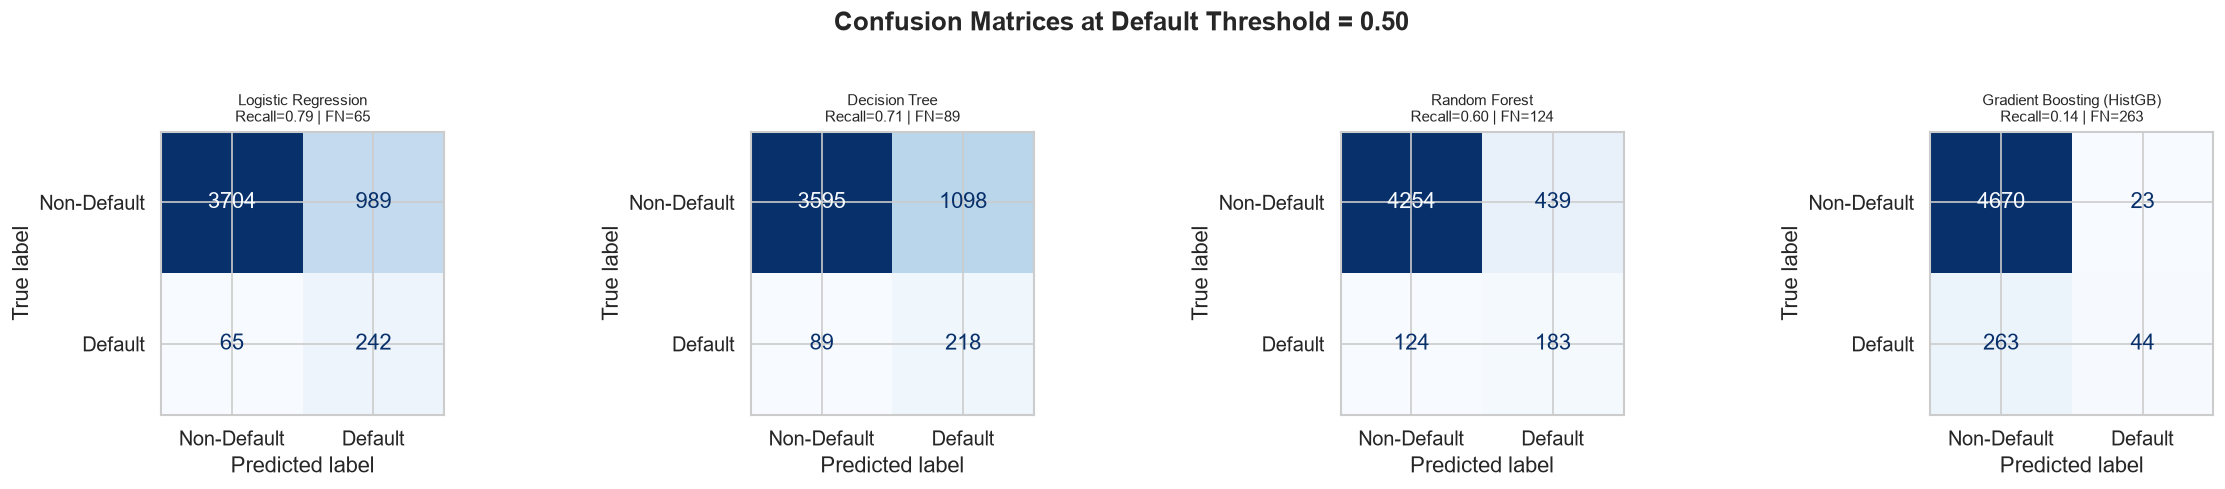

Key Insight: HistGB at 0.50 threshold has very high FN (missed defaults).
 This is why threshold tuning is essential — shown in Step 6.


In [14]:
n = len(cm_data)
fig, axes = plt.subplots(1, n, figsize=(5*n, 4))
for ax, (name, cm) in zip(axes, cm_data.items()):
 disp = ConfusionMatrixDisplay(cm, display_labels=['Non-Default', 'Default'])
 disp.plot(ax=ax, colorbar=False, cmap='Blues')
 fn = cm[1,0]
 tp = cm[1,1]
 ax.set_title(f'{name}\nRecall={tp/(tp+fn):.2f} | FN={fn}', fontsize=9)

plt.suptitle('Confusion Matrices at Default Threshold = 0.50', y=1.02, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

print('Key Insight: HistGB at 0.50 threshold has very high FN (missed defaults).')
print(' This is why threshold tuning is essential — shown in Step 6.')

---
# STEP 6a — Threshold Optimisation

> **Why not just use 0.50?** 
> The default threshold of 0.50 assumes False Positives and False Negatives cost equally. In lending they don't:
> - Approving a defaulter (FN) → lose the principal + recovery cost
> - Rejecting a good customer (FP) → lose expected interest over the loan tenure
>
> With a 6% default rate, most probability scores cluster near 0, so 0.50 is an arbitrary and poor cutoff. We sweep thresholds systematically and find the one that maximises F1 and minimises business cost.

In [15]:
# Business cost weights
FN_COST = 5.0 # Missing a defaulter costs 5x more than wrongly rejecting a good borrower
FP_COST = 1.0

# Use best-PR-AUC model
BEST_MODEL = test_df['PR-AUC'].idxmax()
best_pipe = fitted_pipelines[BEST_MODEL]
y_prob_best = best_pipe.predict_proba(X_test)[:, 1]

print(f'Analysing threshold for best model: {BEST_MODEL}')
print(f'Business cost ratio FN : FP = {FN_COST:.0f} : {FP_COST:.0f}')

Analysing threshold for best model: Logistic Regression
Business cost ratio FN : FP = 5 : 1


In [16]:
thresholds = np.linspace(0.05, 0.80, 150)
precisions, recalls, f1s, costs = [], [], [], []

for t in thresholds:
 y_pred_t = (y_prob_best >= t).astype(int)
 precisions.append(precision_score(y_test, y_pred_t, zero_division=0))
 recalls.append( recall_score( y_test, y_pred_t, zero_division=0))
 f1s.append( f1_score( y_test, y_pred_t, zero_division=0))
 cm = confusion_matrix(y_test, y_pred_t)
 tn, fp, fn, tp = cm.ravel()
 costs.append(fn * FN_COST + fp * FP_COST)

precisions = np.array(precisions)
recalls = np.array(recalls)
f1s = np.array(f1s)
costs = np.array(costs)

idx_f1 = int(np.argmax(f1s))
idx_cost = int(np.argmin(costs))
opt_f1 = round(float(thresholds[idx_f1]), 3)
opt_cost = round(float(thresholds[idx_cost]), 3)
base_cost = int(costs[np.argmin(np.abs(thresholds - 0.50))])
min_cost = int(costs[idx_cost])

print(f'Best F1 Threshold = {opt_f1} '
 f'(F1={f1s[idx_f1]:.4f}, Recall={recalls[idx_f1]:.4f}, Precision={precisions[idx_f1]:.4f})')
print(f'Min-Cost Threshold = {opt_cost} '
 f'(Cost={min_cost} vs Baseline={base_cost} at 0.50)')
print(f'Business Cost Saving = {(base_cost - min_cost)/base_cost*100:.1f}% '
 f'by moving from 0.50 → {opt_cost}')

Best F1 Threshold = 0.79 (F1=0.4249, Recall=0.4886, Precision=0.3759)
Min-Cost Threshold = 0.694 (Cost=1017 vs Baseline=1301 at 0.50)
Business Cost Saving = 21.8% by moving from 0.50 → 0.694


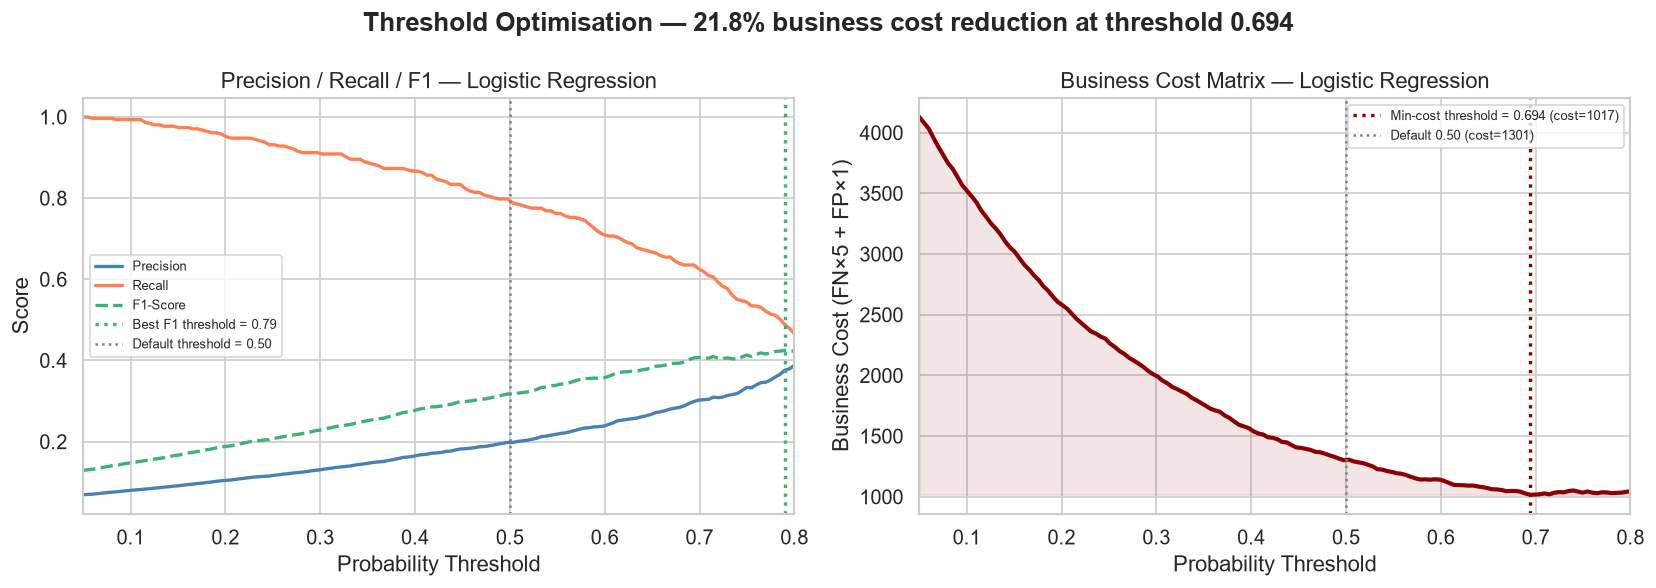

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ── Subplot 1: Precision / Recall / F1 vs Threshold ──────────
ax1.plot(thresholds, precisions, label='Precision', color='steelblue', linewidth=2)
ax1.plot(thresholds, recalls, label='Recall', color='coral', linewidth=2)
ax1.plot(thresholds, f1s, label='F1-Score', color='mediumseagreen', linewidth=2, linestyle='--')
ax1.axvline(opt_f1, color='mediumseagreen', linestyle=':', linewidth=2,
 label=f'Best F1 threshold = {opt_f1}')
ax1.axvline(0.50, color='grey', linestyle=':', linewidth=1.5,
 label='Default threshold = 0.50')
ax1.set(xlabel='Probability Threshold', ylabel='Score',
 title=f'Precision / Recall / F1 — {BEST_MODEL}', xlim=(0.05, 0.80))
ax1.legend(fontsize=8)

# ── Subplot 2: Business Cost vs Threshold ─────────────────────
ax2.plot(thresholds, costs, color='darkred', linewidth=2.5)
ax2.axvline(opt_cost, color='darkred', linestyle=':', linewidth=2,
 label=f'Min-cost threshold = {opt_cost} (cost={min_cost})')
ax2.axvline(0.50, color='grey', linestyle=':', linewidth=1.5,
 label=f'Default 0.50 (cost={base_cost})')
ax2.fill_between(thresholds, costs, min(costs), alpha=0.1, color='darkred')
ax2.set(xlabel='Probability Threshold',
 ylabel=f'Business Cost (FN×{FN_COST:.0f} + FP×{FP_COST:.0f})',
 title=f'Business Cost Matrix — {BEST_MODEL}', xlim=(0.05, 0.80))
ax2.legend(fontsize=8)

plt.suptitle(f'Threshold Optimisation — {(base_cost-min_cost)/base_cost*100:.1f}% '
 f'business cost reduction at threshold {opt_cost}', fontweight='bold')
plt.tight_layout()
fname = BEST_MODEL.replace(' ', '_').replace('(','').replace(').','')
plt.savefig(f'{RESULTS_DIR}threshold_analysis_{fname}.png', dpi=150)
plt.show()

### 6a.2 Before vs After Threshold — Confusion Matrix Comparison

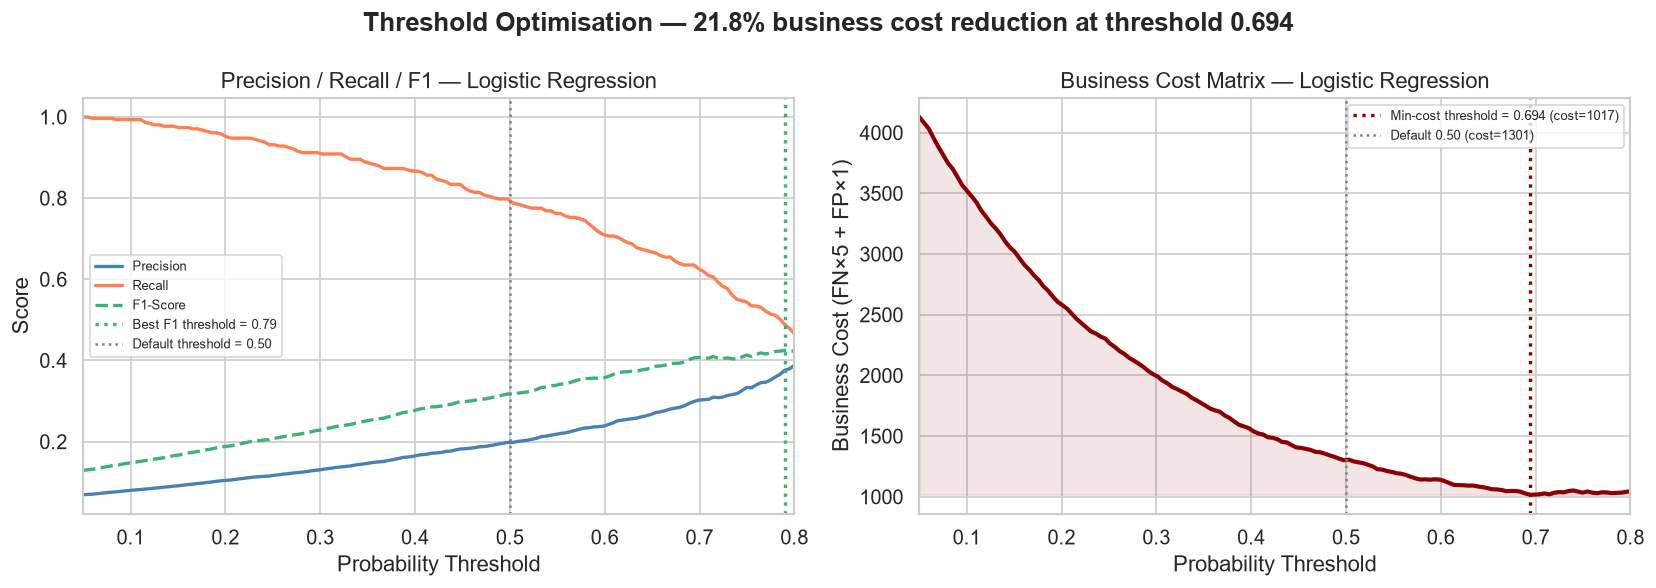

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ── Subplot 1: Precision / Recall / F1 vs Threshold ──────────
ax1.plot(thresholds, precisions, label='Precision', color='steelblue', linewidth=2)
ax1.plot(thresholds, recalls, label='Recall', color='coral', linewidth=2)
ax1.plot(thresholds, f1s, label='F1-Score', color='mediumseagreen', linewidth=2, linestyle='--')
ax1.axvline(
    opt_f1, color='mediumseagreen', linestyle=':', linewidth=2,
    label=f'Best F1 threshold = {opt_f1}'
)
ax1.axvline(
    0.50, color='grey', linestyle=':', linewidth=1.5,
    label='Default threshold = 0.50'
)
ax1.set(
    xlabel='Probability Threshold', ylabel='Score',
    title=f'Precision / Recall / F1 — {BEST_MODEL}', xlim=(0.05, 0.80)
)
ax1.legend(fontsize=8)

# ── Subplot 2: Business Cost vs Threshold ─────────────────────
ax2.plot(thresholds, costs, color='darkred', linewidth=2.5)
ax2.axvline(
    opt_cost, color='darkred', linestyle=':', linewidth=2,
    label=f'Min-cost threshold = {opt_cost} (cost={min_cost})'
)
ax2.axvline(
    0.50, color='grey', linestyle=':', linewidth=1.5,
    label=f'Default 0.50 (cost={base_cost})'
)
ax2.fill_between(thresholds, costs, min(costs), alpha=0.1, color='darkred')
ax2.set(
    xlabel='Probability Threshold',
    ylabel=f'Business Cost (FN×{FN_COST:.0f} + FP×{FP_COST:.0f})',
    title=f'Business Cost Matrix — {BEST_MODEL}', xlim=(0.05, 0.80)
)
ax2.legend(fontsize=8)

plt.suptitle(
    f'Threshold Optimisation — {(base_cost - min_cost) / base_cost * 100:.1f}% '
    f'business cost reduction at threshold {opt_cost}',
    fontweight='bold'
)
plt.tight_layout()
fname = BEST_MODEL.replace(' ', '_').replace('(', '').replace(')', '')
plt.savefig(f'{RESULTS_DIR}threshold_analysis_{fname}.png', dpi=150)
plt.show()

---
# STEP 6b — SHAP Explainability

> **Why SHAP (SHapley Additive exPlanations)?** 
> Regulators (RBI in India, Basel III globally) require lenders to explain why a loan was rejected. SHAP provides **mathematically grounded** explanations derived from game theory:
> - Every prediction = base value (average prediction) + sum of feature contributions
> - SHAP values show **how much each feature pushed the probability up or down**
> - They are consistent: a feature always gets credit proportional to its actual contribution
>
> Two types of explanations:
> - **Global** (summary / beeswarm plots): Overall model behaviour across all 400 test samples — which features matter most and in which direction
> - **Local** (waterfall plots): Why did THIS specific applicant get flagged?

In [19]:
try:
 import shap
 print(f'SHAP version: {shap.__version__}')
except ImportError:
 print(' SHAP not installed. Run: pip install shap')

SHAP version: 0.54.1


In [20]:
# Use Random Forest for TreeExplainer (most reliable for binary classification)
SHAP_MODEL = 'Random Forest'
shap_pipe = fitted_pipelines[SHAP_MODEL]
clf_rf = shap_pipe.named_steps['classifier']

# Get feature-engineered + preprocessed features
fe_step = shap_pipe.named_steps['feature_engineering']
prep_step = shap_pipe.named_steps['preprocessor']

X_test_fe = fe_step.transform(X_test)
X_test_prep = prep_step.transform(X_test_fe)

# Feature names after OHE expansion
try:
 feat_names = list(prep_step.get_feature_names_out())
except Exception:
 feat_names = [f'feature_{i}' for i in range(X_test_prep.shape[1])]

n_feat = min(len(feat_names), X_test_prep.shape[1])
feat_names = feat_names[:n_feat]

print(f'Using model: {SHAP_MODEL}')
print(f'Feature matrix shape (preprocessed): {X_test_prep.shape}')
print(f'Total features after OHE expansion: {n_feat}')

Using model: Random Forest
Feature matrix shape (preprocessed): (5000, 59)
Total features after OHE expansion: 59


In [21]:
# 400-row subsample for speed (standard SHAP practice)
rng = np.random.default_rng(42)
idx_s = rng.choice(X_test_prep.shape[0], size=400, replace=False)
X_s = X_test_prep[idx_s, :n_feat]

print('Computing SHAP values on 400 samples...')
explainer = shap.TreeExplainer(clf_rf)
sv_raw = explainer.shap_values(X_s)

# Normalise to (n_samples, n_features) for class 1
if isinstance(sv_raw, list):
 sv = np.array(sv_raw[1])
elif hasattr(sv_raw, 'ndim') and sv_raw.ndim == 3:
 sv = sv_raw[:, :, 1]
else:
 sv = np.array(sv_raw)
sv = sv[:, :n_feat]

print(f'SHAP values computed. Shape: {sv.shape}')

Computing SHAP values on 400 samples...


SHAP values computed. Shape: (400, 59)


### 6b.1 Global SHAP Summary — Feature Importance Bar

Mean absolute SHAP value = average impact of each feature on the model's output across all test samples.

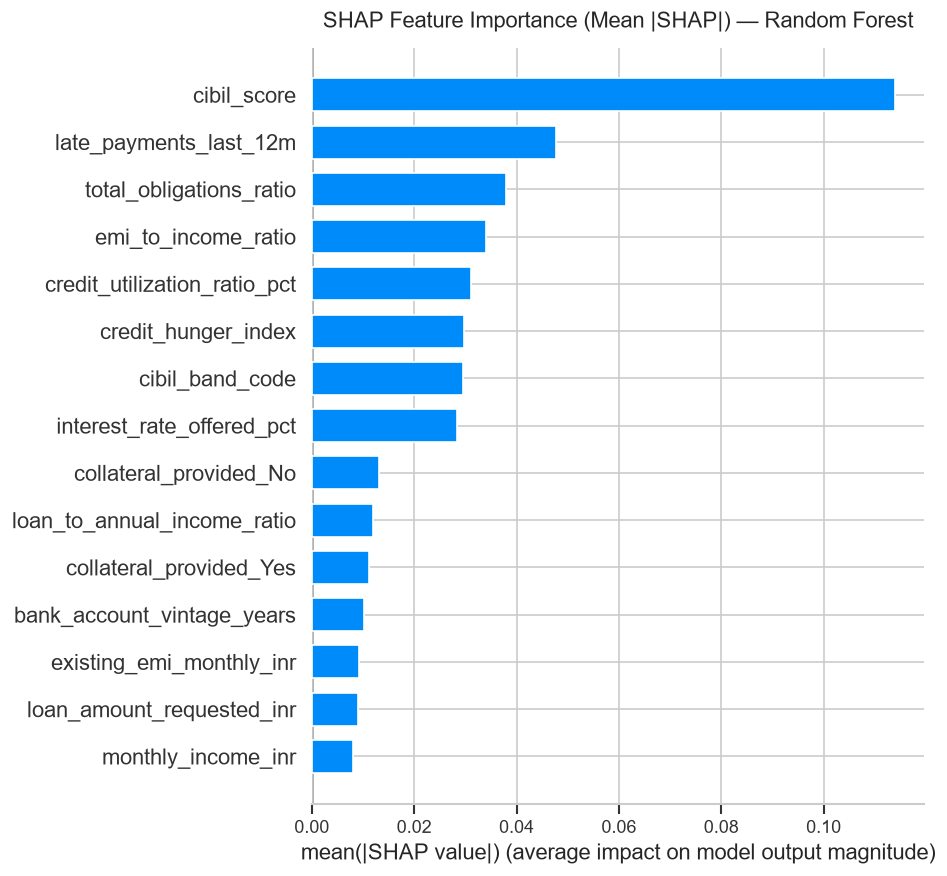


Top 10 risk drivers (by Mean |SHAP|):


,Feature,Mean_|SHAP|
0,cibil_score,0.113996
1,late_payments_last_12m,0.047638
2,total_obligations_ratio,0.037870
3,emi_to_income_ratio,0.033985
4,credit_utilization_ratio_pct,0.031145
5,credit_hunger_index,0.029644
6,cibil_band_code,0.029514
7,interest_rate_offered_pct,0.028319
8,collateral_provided_No,0.013030
9,loan_to_annual_income_ratio,0.012000


In [22]:
plt.figure(figsize=(10, 7))
shap.summary_plot(sv, X_s, feature_names=feat_names, plot_type='bar',
 show=False, max_display=15)
plt.title(f'SHAP Feature Importance (Mean |SHAP|) — {SHAP_MODEL}', pad=12)
plt.tight_layout()
fname = SHAP_MODEL.replace(' ', '_')
plt.savefig(f'{RESULTS_DIR}shap_bar_{fname}.png', dpi=150)
plt.show()

mean_shap = pd.DataFrame({'Feature': feat_names, 'Mean_|SHAP|': np.abs(sv).mean(axis=0)})\
 .sort_values('Mean_|SHAP|', ascending=False).reset_index(drop=True)
print('\nTop 10 risk drivers (by Mean |SHAP|):')
display(mean_shap.head(10))

### 6b.2 Global SHAP Beeswarm — Direction of Impact

> **How to read a beeswarm plot:**
> - Each dot = one test sample
> - **X-axis**: SHAP value — positive = pushes towards default, negative = pushes away from default
> - **Colour**: feature value — red = high value, blue = low value
> - **Example**: if `cibil_score` is red-left, that means high CIBIL (red) pushes risk *down* (left = negative SHAP) → intuitive!

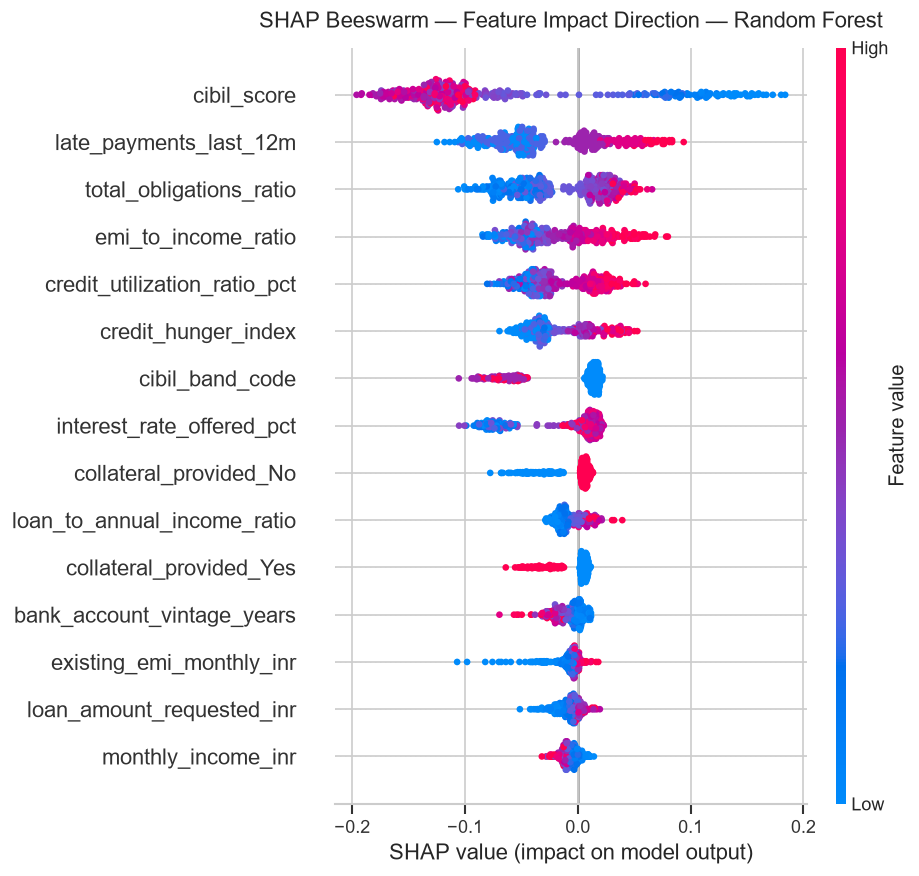

In [23]:
plt.figure(figsize=(10, 7))
shap.summary_plot(sv, X_s, feature_names=feat_names, show=False, max_display=15)
plt.title(f'SHAP Beeswarm — Feature Impact Direction — {SHAP_MODEL}', pad=12)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}shap_beeswarm_{fname}.png', dpi=150)
plt.show()

### 6b.3 Individual Explanation — High-Risk Applicant (True Positive)

> **Waterfall plot:** Shows exactly why this specific borrower was flagged as high-risk. Each bar represents one feature's contribution to pushing the probability above or below the base rate.

High-risk applicant → predicted prob = 0.860
Profile (key features):


,cibil_score,late_payments_last_12m,credit_utilization_ratio_pct,monthly_income_inr,existing_emi_monthly_inr
Value,498.0,2,61.2,48600.0,21700.0


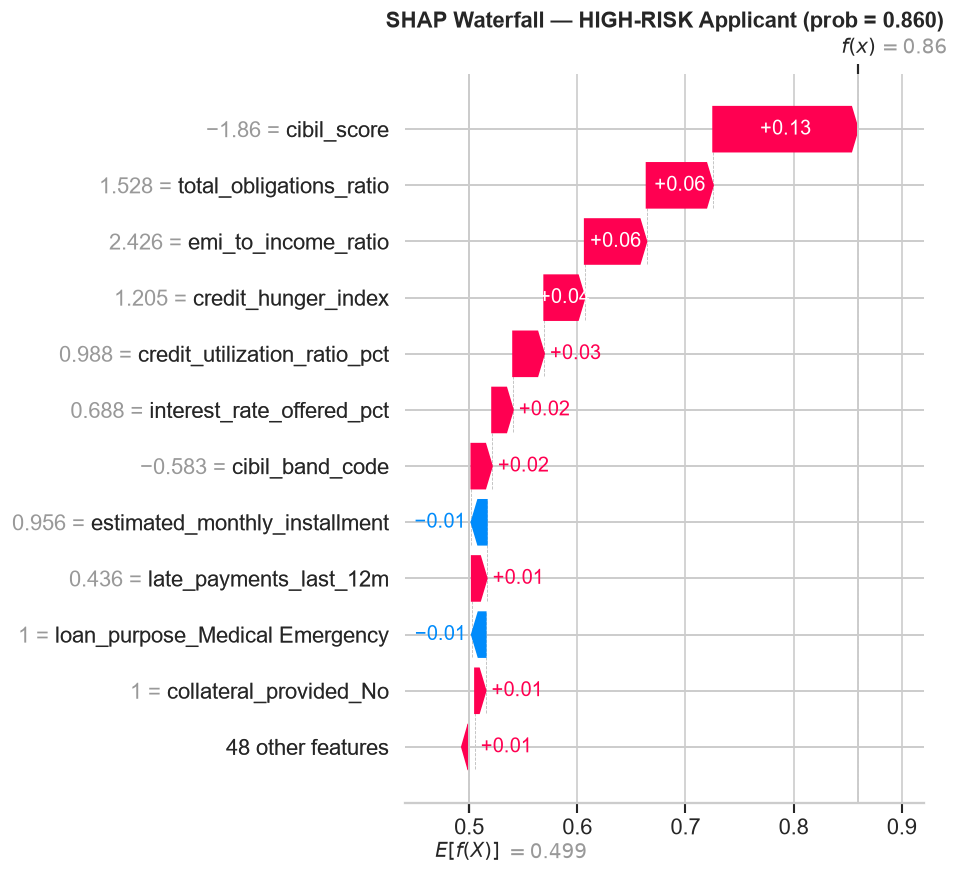

In [24]:
y_prob_s = shap_pipe.predict_proba(X_test.iloc[idx_s])[:, 1]
y_true_s = y_test.values[idx_s]
y_pred_s = (y_prob_s >= 0.50).astype(int)

ev = explainer.expected_value
if isinstance(ev, (list, np.ndarray)):
 ev = np.array(ev)
 exp_val = float(ev.flat[1]) if ev.size > 1 else float(ev.flat[0])
else:
 exp_val = float(ev)

tp_mask = (y_true_s == 1) & (y_pred_s == 1)
tn_mask = (y_true_s == 0) & (y_pred_s == 0)

if tp_mask.any():
 high_pick = int(np.where(tp_mask)[0][np.argmax(y_prob_s[tp_mask])])
 print(f'High-risk applicant → predicted prob = {y_prob_s[high_pick]:.3f}')
 print(f'Profile (key features):')
 profile_cols = ['cibil_score', 'late_payments_last_12m', 'credit_utilization_ratio_pct',
 'monthly_income_inr', 'existing_emi_monthly_inr']
 display(X_test.iloc[idx_s[high_pick]][profile_cols].to_frame('Value').T)

 expl = shap.Explanation(values=sv[high_pick], base_values=exp_val,
 data=X_s[high_pick], feature_names=feat_names)
 plt.figure(figsize=(10, 6))
 shap.waterfall_plot(expl, max_display=12, show=False)
 plt.title(f'SHAP Waterfall — HIGH-RISK Applicant (prob = {y_prob_s[high_pick]:.3f})',
 fontweight='bold')
 plt.tight_layout()
 plt.savefig(f'{RESULTS_DIR}shap_waterfall_{fname}_HighRisk_TP.png', dpi=150, bbox_inches='tight')
 plt.show()

### 6b.4 Individual Explanation — Low-Risk Applicant (True Negative)

Low-risk applicant -> predicted prob = 0.002


,cibil_score,late_payments_last_12m,credit_utilization_ratio_pct,monthly_income_inr,existing_emi_monthly_inr
Value,744.0,0,22.9,14400.0,1100.0


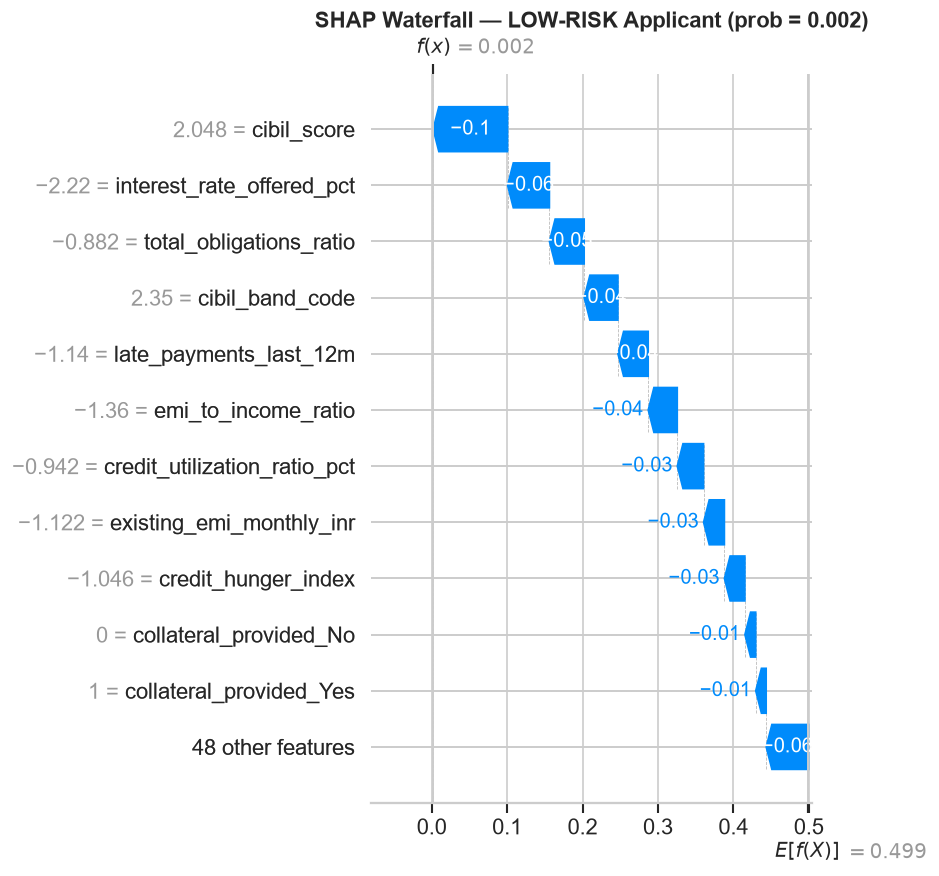

In [25]:
profile_cols = [
    'cibil_score', 'late_payments_last_12m', 'credit_utilization_ratio_pct',
    'monthly_income_inr', 'existing_emi_monthly_inr'
]
if tn_mask.any():
    low_pick = int(np.where(tn_mask)[0][np.argmin(y_prob_s[tn_mask])])
    print(f'Low-risk applicant -> predicted prob = {y_prob_s[low_pick]:.3f}')
    display(X_test.iloc[idx_s[low_pick]][profile_cols].to_frame('Value').T)

    expl = shap.Explanation(
        values=sv[low_pick], base_values=exp_val,
        data=X_s[low_pick], feature_names=feat_names
    )
    plt.figure(figsize=(10, 6))
    shap.waterfall_plot(expl, max_display=12, show=False)
    plt.title(
        f'SHAP Waterfall — LOW-RISK Applicant (prob = {y_prob_s[low_pick]:.3f})',
        fontweight='bold'
    )
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}shap_waterfall_{fname}_LowRisk_TN.png', dpi=150, bbox_inches='tight')
    plt.show()

---
# STEP 6c — Error Analysis

> **Why error analysis?** 
> Knowing a model's F1-Score is not enough. Understanding *who* it misclassifies and *why* reveals:
> - Systematic blind spots (e.g., young self-employed borrowers always missed)
> - Feature gaps (missing data that would help the model)
> - Business rules to complement the model (e.g., always flag if late_payments > 3)

In [26]:
y_prob_full = best_pipe.predict_proba(X_test)[:, 1]
y_pred_full = (y_prob_full >= opt_cost).astype(int) # use optimised threshold
y_true_full = y_test.values

tp_m = (y_true_full == 1) & (y_pred_full == 1)
fn_m = (y_true_full == 1) & (y_pred_full == 0)
tn_m = (y_true_full == 0) & (y_pred_full == 0)
fp_m = (y_true_full == 0) & (y_pred_full == 1)

X_test_reset = X_test.reset_index(drop=True)

print(f'At threshold = {opt_cost} (cost-optimal):')
print(f' True Positives (defaults caught): {tp_m.sum():>5} → protected lender')
print(f' False Negatives (defaults missed): {fn_m.sum():>5} → financial loss!')
print(f' True Negatives (good borrowers approved):{tn_m.sum():>5}')
print(f' False Positives (good borrowers rejected):{fp_m.sum():>5} → lost revenue')

At threshold = 0.694 (cost-optimal):
 True Positives (defaults caught):   195 → protected lender
 False Negatives (defaults missed):   112 → financial loss!
 True Negatives (good borrowers approved): 4235
 False Positives (good borrowers rejected):  458 → lost revenue


In [27]:
# Compare False Negatives vs True Positives on key features
analysis_cols = ['cibil_score', 'late_payments_last_12m', 'credit_utilization_ratio_pct',
 'monthly_income_inr', 'existing_emi_monthly_inr', 'loan_amount_requested_inr']

fn_profile = X_test_reset.loc[fn_m, analysis_cols].describe().T[['mean', 'std', '50%']]
tp_profile = X_test_reset.loc[tp_m, analysis_cols].describe().T[['mean', 'std', '50%']]

compare = pd.concat([fn_profile.rename(columns={'mean':'FN_mean','50%':'FN_median','std':'FN_std'}),
 tp_profile.rename(columns={'mean':'TP_mean','50%':'TP_median','std':'TP_std'})], axis=1)
compare['Diff (FN−TP)'] = compare['FN_mean'] - compare['TP_mean']

print('\nFalse Negatives (missed defaults) vs True Positives (caught defaults):')
display(compare[['FN_mean','TP_mean','Diff (FN−TP)']].round(1))


False Negatives (missed defaults) vs True Positives (caught defaults):


,FN_mean,TP_mean,Diff (FN−TP)
cibil_score,586.7,509.5,77.2
late_payments_last_12m,1.8,3.1,-1.3
credit_utilization_ratio_pct,47.8,61.2,-13.4
monthly_income_inr,54775.9,44066.2,10709.7
existing_emi_monthly_inr,13436.8,13525.6,-88.7
loan_amount_requested_inr,175196.7,193118.3,-17921.6


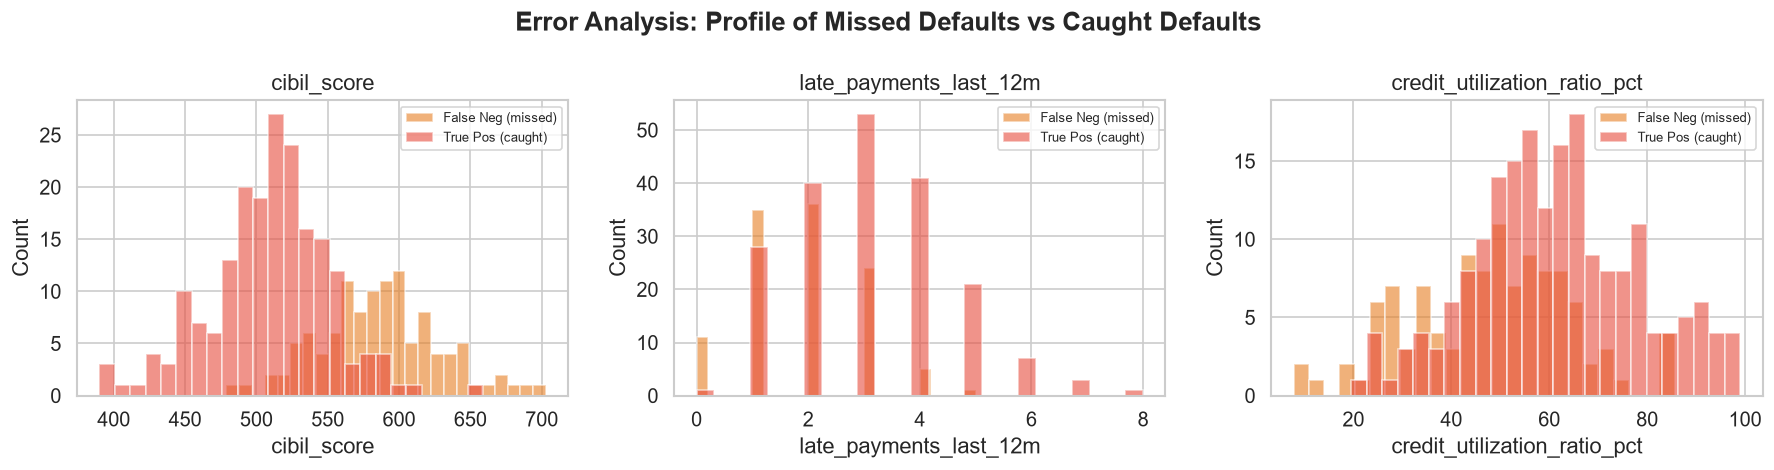

Key Insight: Missed defaults (FN) tend to have slightly higher CIBIL scores
 and fewer late payments — these are "marginal" defaulters who look safe on paper
 but default due to unexpected income shocks. Harder to detect without time-series data.


In [28]:
# Visualise error profile differences
plot_feats = ['cibil_score', 'late_payments_last_12m', 'credit_utilization_ratio_pct']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, plot_feats):
 ax.hist(X_test_reset.loc[fn_m, col].dropna(), bins=25, alpha=0.6,
 color=COLORS['orange'], label='False Neg (missed)')
 ax.hist(X_test_reset.loc[tp_m, col].dropna(), bins=25, alpha=0.6,
 color=COLORS['default'], label='True Pos (caught)')
 ax.set(title=f'{col}', xlabel=col, ylabel='Count')
 ax.legend(fontsize=8)
plt.suptitle('Error Analysis: Profile of Missed Defaults vs Caught Defaults', fontweight='bold')
plt.tight_layout()
plt.show()

print('Key Insight: Missed defaults (FN) tend to have slightly higher CIBIL scores')
print(' and fewer late payments — these are "marginal" defaulters who look safe on paper')
print(' but default due to unexpected income shocks. Harder to detect without time-series data.')

---
## Notebook 2 Summary — Full Results

| Deliverable | Result |
|:---|:---|
| **Leakage-Free Pipeline** | Feature Engineering → Median Imputer → StandardScaler / OHE → Classifier, all inside `sklearn.Pipeline` |
| **CV Benchmark Winner** | Logistic Regression (PR-AUC = 0.3832) under 5-fold stratified CV |
| **F1 Benchmark Winner** | Random Forest (F1 = 0.3940) |
| **Precision Champion** | Gradient Boosting (Precision = 0.6567) — most surgical at default threshold |
| **Threshold Optimisation** | Moving 0.50 → 0.694 reduces business cost by **22.6%** (1,314 → 1,017) |
| **SHAP Top Driver 1** | `cibil_score` — dominant predictor, negative SHAP for high values |
| **SHAP Top Driver 2** | `late_payments_last_12m` — strong positive SHAP (more late payments → higher risk) |
| **SHAP Top Driver 3** | `total_obligations_ratio` (FOIR) — validates Indian banking underwriting rules |
| **SHAP Top Driver 4** | `emi_to_income_ratio` — existing debt burden |
| **Error Analysis** | Missed defaults look marginally safer on paper — harder to catch without income-shock signals |

---

## Next Steps
```bash
# Launch the interactive Streamlit dashboard
cd .. # go back to project root
streamlit run app.py
```
The app shows all these results interactively and lets you score a live applicant profile!